# NOTEBOOK 2 – LÀM SẠCH & TIỀN XỬ LÝ DỮ LIỆU (NV4)
**Đề tài:** Sử dụng thuật toán Naive Bayes để phân loại tin nhắn lừa đảo trực tuyến
**Dataset:** D1 – SMS Phishing Dataset (Mishra & Soni) – nhãn `ham / spam / smishing`

## Quy trình tổng thể
```
Dataset_5971.csv (gốc, KHÔNG sửa)
        │
        ▼  Bước 1  Chuẩn hóa nhãn + cột cờ (yes/No -> 1/0)
        ▼  Bước 2  Làm sạch văn bản (chữ thường, gộp khoảng trắng, lỗi �)
        ▼  Bước 3  Loại dòng rỗng
        ▼  Bước 4  Xử lý nội dung bị gán 2 nhãn khác nhau (xung đột)
        ▼  Bước 5  Loại dòng trùng (cùng nội dung + cùng nhãn)
        ▼  Bước 6  Ghi bảng số mẫu trước/sau
        ▼  Bước 7  Lưu dataset sạch
        ▼  Bước 8  Chia train/test (stratify, random_state cố định)
        ▼
 data/processed/{sms_phishing_clean, train, test}.csv
```

## Các nguyên tắc xuyên suốt
1. **Không sửa file gốc.** Mọi thay đổi làm trên bản sao trong bộ nhớ.
2. **Mỗi bước đều đếm lại số mẫu** để biết bước nào làm mất bao nhiêu dòng.
3. **Không làm thay đổi ý nghĩa nhãn.** Chỉ đổi cách *viết* (`Spam` → `spam`), không đổi nhãn nào sang nhãn khác.
4. **Loại trùng TRƯỚC khi chia train/test**, nếu không cùng một tin có thể nằm ở cả hai tập → mô hình “nhìn thấy đáp án”, điểm số cao giả tạo (gọi là *rò rỉ dữ liệu – data leakage*).

> Cần chạy xong Notebook 1 (không bắt buộc, nhưng nên) để hiểu vì sao cần các bước dưới đây.

## Bước 0. Cấu hình và nhập thư viện
Các **tham số quyết định** (chính sách xung đột nhãn, tỷ lệ test, random_state) đặt hết ở ô này để cả nhóm dễ thống nhất và dễ ghi vào báo cáo.

In [1]:
import re, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split

# ====== ĐƯỜNG DẪN ======
DATA_PATH     = Path("data/raw/Dataset_5971.csv")
PROCESSED_DIR = Path("data/processed")
OUT_TABLES    = Path("outputs/tables")
OUT_FIGS      = Path("outputs/figures")
for p in (PROCESSED_DIR, OUT_TABLES, OUT_FIGS):
    p.mkdir(parents=True, exist_ok=True)

# ====== THAM SỐ QUYẾT ĐỊNH (cả nhóm cần thống nhất) ======
LABELS_OK = ["ham", "spam", "smishing"]
FLAG_COLS = ["URL", "EMAIL", "PHONE"]

# Cách xử lý nội dung bị gán 2 nhãn khác nhau:
#   "drop"            : loại bỏ TẤT CẢ các dòng đó  (khuyến nghị – an toàn, không phải đoán nhãn)
#   "prefer_smishing" : giữ bản gán smishing, bỏ bản còn lại
#   "prefer_spam"     : giữ bản gán spam, bỏ bản còn lại
CONFLICT_POLICY = "drop"

TEST_SIZE    = 0.20      # 80% train / 20% test
RANDOM_STATE = 42        # hạt giống ngẫu nhiên – GHI VÀO BÁO CÁO
print("Chính sách xung đột:", CONFLICT_POLICY, "| test_size:", TEST_SIZE, "| random_state:", RANDOM_STATE)

Chính sách xung đột: drop | test_size: 0.2 | random_state: 42


## Bước 0b. Đọc file gốc
Cách đọc giống Notebook 1 (`dtype=str`, `keep_default_na=False`) để không làm mất dữ liệu ngay từ lúc đọc.

In [2]:
def read_csv_safe(path):
    last_err = None
    for enc in ["utf-8", "utf-8-sig", "cp1252", "latin-1"]:
        try:
            return pd.read_csv(path, encoding=enc, dtype=str, keep_default_na=False), enc
        except UnicodeDecodeError as e:
            last_err = e
    raise last_err

assert DATA_PATH.exists(), f"Không thấy {DATA_PATH}. Hãy đặt Dataset_5971.csv vào data/raw/"
df_raw, enc = read_csv_safe(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()
print("Encoding:", enc, "| kích thước gốc:", df_raw.shape)

# ---- Công cụ ghi nhật ký số mẫu sau mỗi bước ----
log = []
def snapshot(step, d, label_col):
    # Ghi số mẫu tổng và theo từng nhãn sau 1 bước xử lý
    vc = d[label_col].astype(str).str.strip().str.lower().value_counts()
    row = {"Bước xử lý": step, "Tổng số mẫu": len(d)}
    for l in LABELS_OK:
        row[l] = int(vc.get(l, 0))
    log.append(row)

snapshot("0. Dữ liệu gốc", df_raw, "LABEL")

Encoding: utf-8 | kích thước gốc: (5971, 5)


## Bước 1. Chuẩn hóa nhãn và các cột cờ (URL / EMAIL / PHONE)

**Vì sao?** Ở Phần 2 đã phát hiện nhãn viết lẫn lộn: `spam` (466) và `Spam` (23); `Smishing` (616) và `smishing` (22). Với máy tính, `Spam` ≠ `spam` nên nếu không sửa, một lớp bị tách làm hai.

**Làm gì?**
* `LABEL`: bỏ khoảng trắng đầu/cuối, đổi sang chữ thường → chỉ còn đúng 3 giá trị `ham`, `spam`, `smishing`.
* `URL`, `EMAIL`, `PHONE`: đổi `yes/No` (lẫn hoa/thường) → số `1/0`.
* Thêm `label_id` (ham=0, spam=1, smishing=2) để thuận tiện khi huấn luyện. Đây chỉ là **mã số của cùng một nhãn**, không đổi ý nghĩa.

**Kiểm tra an toàn:** nếu sau chuẩn hóa còn nhãn lạ, code sẽ **dừng lại báo lỗi** chứ không tự đoán.

In [3]:
df = df_raw.copy()

df["label"] = df["LABEL"].str.strip().str.lower()
unknown = set(df["label"]) - set(LABELS_OK)
assert not unknown, f"Có nhãn lạ cần xem lại thủ công: {unknown}"

LABEL2ID = {"ham": 0, "spam": 1, "smishing": 2}
df["label_id"] = df["label"].map(LABEL2ID)

for c in FLAG_COLS:
    v = df[c].str.strip().str.lower()
    bad = set(v) - {"yes", "no"}
    assert not bad, f"Cột {c} có giá trị lạ: {bad}"
    df[c.lower()] = (v == "yes").astype(int)

print("Nhãn trước:", df_raw["LABEL"].value_counts().to_dict())
print("Nhãn sau  :", df["label"].value_counts().to_dict())
snapshot("1. Chuẩn hóa nhãn & cột cờ", df, "label")

Nhãn trước: {'ham': 4844, 'Smishing': 616, 'spam': 466, 'Spam': 23, 'smishing': 22}
Nhãn sau  : {'ham': 4844, 'smishing': 638, 'spam': 489}


## Bước 2. Làm sạch văn bản

Tạo **hai** cột văn bản để nhóm chọn dùng ở bước huấn luyện:

| Cột | Nội dung | Khi nào dùng |
|---|---|---|
| `text_clean` | Chữ thường + gộp khoảng trắng + bỏ ký tự lỗi `�`. **Giữ nguyên URL và số.** | Cột chính (khuyến nghị). |
| `text_norm` | Như `text_clean` nhưng thay URL → `urltoken`, email → `emailtoken`, dãy ≥ 7 chữ số → `phonetoken`, số còn lại → `numtoken`. | Thử nghiệm so sánh. |

**Vì sao cân nhắc giữ URL/số?** Tin lừa đảo thường chứa link lạ hoặc số điện thoại/số tiền (“call 0906…”, “£1000 prize”). Với Naive Bayes, *có* link/số là tín hiệu mạnh. Nhưng mỗi link/số cụ thể hiếm khi lặp lại, nên `text_norm` gom chúng về 1 từ chung để mô hình học được quy luật “tin có link thì…”. Cả hai cách đều **không xóa thông tin**, chỉ khác mức khái quát. Khi huấn luyện nên thử cả hai rồi so sánh.

**Các thao tác trên `text_clean` (theo thứ tự):**
1. Thay ký tự lỗi `�` (U+FFFD) và ký tự vô hình (zero-width) bằng khoảng trắng. *Không đoán lại ký tự gốc vì không biết nó là gì.*
2. Đổi toàn bộ sang chữ thường.
3. Gộp mọi chuỗi khoảng trắng/tab/xuống dòng liền nhau thành **1 dấu cách**.
4. Cắt khoảng trắng đầu và cuối.

> Không xóa dấu câu, không xóa stop-word ở bước này: việc đó thuộc bước vector hóa (CountVectorizer/TF-IDF) để mọi người còn quyền lựa chọn.

In [4]:
ZERO_WIDTH = "[\u200b\u200c\u200d\ufeff]"
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b")
URL_RE   = re.compile(r"(?:https?://|www\.)\S+"
                      r"|\b[a-z0-9][a-z0-9\-]*(?:\.[a-z0-9\-]+)*\.(?:com|net|org|info|biz|co|uk|ly|me|xyz|top|us|in|io)\b(?:/\S*)?",
                      re.I)
LONGNUM_RE = re.compile(r"\d{7,}")                 # dãy >= 7 chữ số (thường là số điện thoại/mã)
NUM_RE     = re.compile(r"\d+(?:[.,]\d+)*")        # số còn lại (giá tiền, năm, ...)

def clean_text(s: str) -> str:
    s = re.sub(ZERO_WIDTH, " ", s)
    s = s.replace("\ufffd", " ")
    s = s.lower()
    s = re.sub(r"\s+", " ", s).strip()
    return s

def normalize_tokens(s: str) -> str:
    # s đã là text_clean. Thay email/URL/số bằng token chung.
    s = EMAIL_RE.sub(" emailtoken ", s)
    s = URL_RE.sub(" urltoken ", s)
    s = LONGNUM_RE.sub(" phonetoken ", s)
    s = NUM_RE.sub(" numtoken ", s)
    return re.sub(r"\s+", " ", s).strip()

df["text_clean"] = df["TEXT"].map(clean_text)
df["text_norm"]  = df["text_clean"].map(normalize_tokens)

# ---- Xem thử vài dòng trước/sau để kiểm tra bằng mắt ----
demo = df.loc[df["TEXT"].str.contains("\ufffd|http|www\\.|\\d{7,}", regex=True)].head(5)
for _, r in demo.iterrows():
    print("GỐC      :", repr(r["TEXT"][:150]))
    print("text_clean:", r["text_clean"][:150])
    print("text_norm :", r["text_norm"][:150])
    print("-" * 80)

snapshot("2. Làm sạch văn bản (chưa bỏ dòng)", df, "label")

GỐC      : "What's up? Do you want me to come online? If you are free we can talk sometime�"
text_clean: what's up? do you want me to come online? if you are free we can talk sometime
text_norm : what's up? do you want me to come online? if you are free we can talk sometime
--------------------------------------------------------------------------------
GỐC      : 'Please Stay At Home. To encourage the notion of staying at home. All tax-paying citizens are entitled to �305.96 or more emergency refund. smsg.io/fCV'
text_clean: please stay at home. to encourage the notion of staying at home. all tax-paying citizens are entitled to 305.96 or more emergency refund. smsg.io/fcvb
text_norm : please stay at home. to encourage the notion of staying at home. all tax-paying citizens are entitled to numtoken or more emergency refund. urltoken
--------------------------------------------------------------------------------
GỐC      : 'BankOfAmerica Alert 137943. Please follow http://bit.do/cgjK-an

## Bước 3. Loại dòng rỗng
Dòng mà `text_clean` rỗng (sau khi làm sạch) không có thông tin để học → bỏ. Theo Phần 2 dữ liệu gốc không có dòng rỗng nên dự kiến **0 dòng bị loại**, nhưng vẫn kiểm tra để chắc chắn.

In [5]:
n_before = len(df)
empty_mask = df["text_clean"].str.len() == 0
print("Số dòng rỗng:", int(empty_mask.sum()))
df = df.loc[~empty_mask].copy()
print(f"{n_before:,} -> {len(df):,} dòng")
snapshot("3. Loại dòng rỗng", df, "label")

Số dòng rỗng: 0
5,971 -> 5,971 dòng


## Bước 4. Xử lý nội dung bị gán nhiều nhãn khác nhau (xung đột nhãn)

**Vấn đề (đã thấy ở Phần 2):** có 34 nội dung giống hệt nhau nhưng một bản gán `spam`, một bản gán `smishing`. Nếu giữ cả hai, mô hình nhận hai “đáp án” trái ngược cho cùng một đầu vào → nhiễu, và khi chia ngẫu nhiên, hai bản có thể rơi vào train và test khác nhau.

**Ba cách xử lý:**
| `CONFLICT_POLICY` | Ý nghĩa | Ưu | Nhược |
|---|---|---|---|
| `"drop"` (khuyến nghị) | Bỏ hết các dòng xung đột | Không phải đoán nhãn, không làm sai ý nghĩa | Mất ~68 dòng |
| `"prefer_smishing"` | Giữ bản smishing | Thiên về an toàn (thà báo nhầm còn hơn bỏ sót) | Có thể gán nhãn nặng hơn thực tế |
| `"prefer_spam"` | Giữ bản spam | Ngược lại | Có thể bỏ sót lừa đảo |

Danh sách các nội dung xung đột được **lưu ra file riêng** để cả nhóm xem lại và thống nhất.

In [6]:
g = df.groupby("text_clean")["label"].nunique()
conflict_texts = g[g > 1].index
conflict_rows = (df[df["text_clean"].isin(conflict_texts)]
                   .sort_values(["text_clean", "label"])
                   [["text_clean", "label"]])
print(f"Số nội dung xung đột: {len(conflict_texts)} | số dòng liên quan: {len(conflict_rows)}")
print(conflict_rows.groupby("text_clean")["label"].apply(lambda x: " + ".join(sorted(set(x)))).value_counts())

conflict_rows.to_csv(OUT_TABLES / "08_noi_dung_xung_dot_nhan.csv", index=False, encoding="utf-8-sig")

in_conflict = df["text_clean"].isin(conflict_texts)
if CONFLICT_POLICY == "drop":
    keep = ~in_conflict
elif CONFLICT_POLICY in ("prefer_smishing", "prefer_spam"):
    preferred = CONFLICT_POLICY.replace("prefer_", "")
    # giữ dòng không xung đột + dòng xung đột mang nhãn ưu tiên. Nội dung không có nhãn ưu tiên sẽ bị loại hẳn.
    keep = (~in_conflict) | (df["label"] == preferred)
else:
    raise ValueError("CONFLICT_POLICY không hợp lệ")

df = df.loc[keep].copy()
print(f"Chính sách '{CONFLICT_POLICY}': còn {len(df):,} dòng")
snapshot(f"4. Xử lý xung đột nhãn ({CONFLICT_POLICY})", df, "label")

Số nội dung xung đột: 34 | số dòng liên quan: 68
label
smishing + spam    34
Name: count, dtype: int64
Chính sách 'drop': còn 5,903 dòng


## Bước 5. Loại dòng trùng (cùng nội dung + cùng nhãn)
* So sánh trên **`text_clean`** (đã chữ thường + gộp khoảng trắng) nên bắt được cả các bản chỉ khác hoa/thường hoặc khoảng trắng.
* Giữ lại **bản đầu tiên** (`keep="first"`), bỏ các bản sau.
* Tin trùng lặp nhiều lần sẽ làm Naive Bayes “đếm lặp” từ của tin đó → lệch xác suất, và gây rò rỉ dữ liệu khi chia train/test.

In [7]:
n_before = len(df)
df = df.drop_duplicates(subset=["text_clean", "label"], keep="first").copy()
print(f"{n_before:,} -> {len(df):,} dòng (loại {n_before - len(df):,} dòng trùng)")

# Kiểm tra an toàn: sau bước này không còn nội dung nào lặp lại
assert not df["text_clean"].duplicated().any(), "Vẫn còn nội dung trùng!"
snapshot("5. Loại dòng trùng cùng nhãn", df, "label")

5,903 -> 5,797 dòng (loại 106 dòng trùng)


## Bước 6. Bảng số mẫu **trước / sau** xử lý (sản phẩm bàn giao)
Bảng 1 – số mẫu sau từng bước. Bảng 2 – so sánh gọn: gốc vs sạch, theo từng nhãn, kèm số dòng bị loại và % bị loại.

In [8]:
log_df = pd.DataFrame(log)
log_df["Số dòng bị loại ở bước này"] = (log_df["Tổng số mẫu"].shift(1) - log_df["Tổng số mẫu"]).fillna(0).astype(int)
display(log_df)

before = log_df.iloc[0]; after = log_df.iloc[-1]
summary = pd.DataFrame({
    "Nhãn": LABELS_OK + ["Tổng"],
    "Trước xử lý": [before[l] for l in LABELS_OK] + [before["Tổng số mẫu"]],
    "Sau xử lý":   [after[l]  for l in LABELS_OK] + [after["Tổng số mẫu"]],
})
summary["Số mẫu bị loại"] = summary["Trước xử lý"] - summary["Sau xử lý"]
summary["% bị loại"] = (summary["Số mẫu bị loại"] / summary["Trước xử lý"] * 100).round(2)
summary["% trước"] = (summary["Trước xử lý"] / summary.iloc[-1]["Trước xử lý"] * 100).round(2)
summary["% sau"]   = (summary["Sau xử lý"]   / summary.iloc[-1]["Sau xử lý"]   * 100).round(2)
display(summary)

log_df.to_csv(OUT_TABLES / "09_so_mau_theo_tung_buoc_xu_ly.csv", index=False, encoding="utf-8-sig")
summary.to_csv(OUT_TABLES / "10_so_mau_truoc_sau_xu_ly.csv", index=False, encoding="utf-8-sig")

,Bước xử lý,Tổng số mẫu,ham,spam,smishing,Số dòng bị loại ở bước này
0,0. Dữ liệu gốc,5971,4844,489,638,0
1,1. Chuẩn hóa nhãn & cột cờ,5971,4844,489,638,0
2,2. Làm sạch văn bản (chưa bỏ dòng),5971,4844,489,638,0
3,3. Loại dòng rỗng,5971,4844,489,638,0
4,4. Xử lý xung đột nhãn (drop),5903,4844,455,604,68
5,5. Loại dòng trùng cùng nhãn,5797,4834,435,528,106


,Nhãn,Trước xử lý,Sau xử lý,Số mẫu bị loại,% bị loại,% trước,% sau
0,ham,4844,4834,10,0.21,81.13,83.39
1,spam,489,435,54,11.04,8.19,7.50
2,smishing,638,528,110,17.24,10.68,9.11
3,Tổng,5971,5797,174,2.91,100.00,100.00


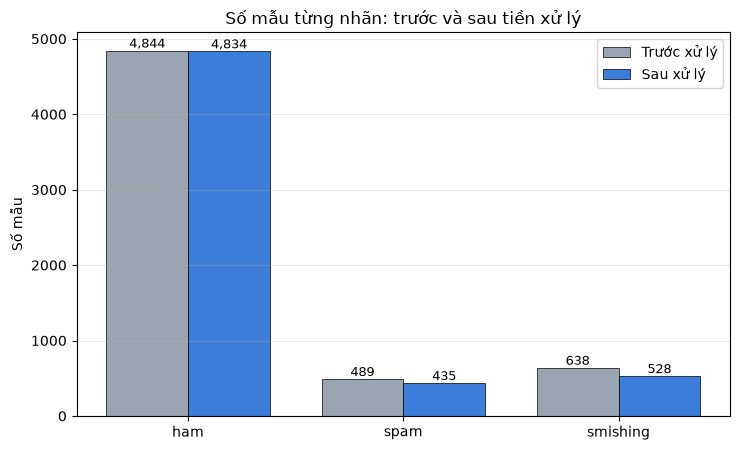

In [9]:
# Biểu đồ so sánh trước/sau theo nhãn
x = np.arange(len(LABELS_OK)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4.6))
b1 = ax.bar(x - w/2, summary.loc[:2, "Trước xử lý"], w, label="Trước xử lý", color="#9AA5B1", edgecolor="black", linewidth=0.5)
b2 = ax.bar(x + w/2, summary.loc[:2, "Sau xử lý"],   w, label="Sau xử lý",   color="#3B7DD8", edgecolor="black", linewidth=0.5)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(LABELS_OK)
ax.set_ylabel("Số mẫu"); ax.set_title("Số mẫu từng nhãn: trước và sau tiền xử lý")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_FIGS / "04_so_mau_truoc_sau_xu_ly.png", dpi=200); plt.show()

## Bước 7. Lưu dataset sạch
Giữ lại các cột cần thiết, thêm `orig_idx` (vị trí dòng trong file gốc, đếm từ 0) để **truy vết ngược** về dữ liệu gốc khi cần.
Lưu bằng `utf-8`; khi đọc lại dùng `pd.read_csv(path)` là đủ.

In [10]:
clean = (df.reset_index().rename(columns={"index": "orig_idx"})
           [["orig_idx", "label", "label_id", "text_clean", "text_norm", "url", "email", "phone"]]
           .reset_index(drop=True))
clean.insert(0, "id", np.arange(1, len(clean) + 1))

CLEAN_PATH = PROCESSED_DIR / "sms_phishing_clean.csv"
clean.to_csv(CLEAN_PATH, index=False, encoding="utf-8")
json.dump(LABEL2ID, open(PROCESSED_DIR / "label_mapping.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

print("Đã lưu:", CLEAN_PATH, "| kích thước:", clean.shape)
clean.head()

Đã lưu: data\processed\sms_phishing_clean.csv | kích thước: (5797, 9)


,id,orig_idx,label,label_id,text_clean,text_norm,url,email,phone
0,1,0,ham,0,your opinion about me? 1. over 2. jada 3. kusr...,your opinion about me? numtoken . over numtoke...,0,0,0
1,2,1,ham,0,what's up? do you want me to come online? if y...,what's up? do you want me to come online? if y...,0,0,0
2,3,2,ham,0,so u workin overtime nigpun?,so u workin overtime nigpun?,0,0,0
3,4,3,ham,0,"also sir, i sent you an email about how to log...","also sir, i sent you an email about how to log...",0,0,0
4,5,4,smishing,2,please stay at home. to encourage the notion o...,please stay at home. to encourage the notion o...,0,0,0


## Bước 8. Chia train/test có `stratify`, ghi `random_state`

**Giải thích các tham số quan trọng:**
* `test_size=0.2` → 20% làm tập kiểm tra, 80% làm tập huấn luyện.
* `stratify=y` → **chia theo tầng**: mỗi nhãn được chia theo đúng tỷ lệ 80/20. Bắt buộc vì dữ liệu mất cân bằng; nếu chia ngẫu nhiên thuần, lớp nhỏ (spam, smishing) có thể bị lệch trong tập test.
* `random_state=42` → cố định hạt giống ngẫu nhiên → **ai chạy lại cũng ra đúng cùng một cách chia** (tái lập được). Con số 42 phải được ghi vào báo cáo.
* `shuffle=True` (mặc định) → xáo trộn trước khi chia.

**Lưu ý cho giai đoạn sau:** tập test chỉ dùng để đánh giá cuối cùng, không dùng để chọn tham số. Nếu cần chọn tham số (vd `alpha` của Naive Bayes) hãy dùng cross-validation *trên tập train*.

In [11]:
X = clean[["id", "text_clean", "text_norm", "url", "email", "phone"]]
y = clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    stratify=y,                 # giữ nguyên tỷ lệ nhãn ở cả 2 tập
    random_state=RANDOM_STATE,  # tái lập kết quả
    shuffle=True,
)

train_df = X_train.assign(label=y_train, label_id=y_train.map(LABEL2ID)).reset_index(drop=True)
test_df  = X_test.assign(label=y_test,  label_id=y_test.map(LABEL2ID)).reset_index(drop=True)

train_df.to_csv(PROCESSED_DIR / "train.csv", index=False, encoding="utf-8")
test_df.to_csv(PROCESSED_DIR / "test.csv",  index=False, encoding="utf-8")
print(f"Train: {len(train_df):,} | Test: {len(test_df):,} | Tổng: {len(train_df)+len(test_df):,}")

Train: 4,637 | Test: 1,160 | Tổng: 5,797


### Kiểm tra việc chia có đúng không
1. Tỷ lệ nhãn ở train và test phải **gần giống nhau** và giống tập sạch.
2. **Không được có tin nào xuất hiện ở cả train lẫn test** (kiểm tra rò rỉ).

In [12]:
def dist(d, name):
    vc = d["label"].value_counts().reindex(LABELS_OK).fillna(0).astype(int)
    out = pd.DataFrame({f"{name} – số mẫu": vc, f"{name} – %": (vc / vc.sum() * 100).round(2)})
    return out

split_table = pd.concat([dist(clean, "Toàn bộ sạch"), dist(train_df, "Train"), dist(test_df, "Test")], axis=1)
split_table.loc["Tổng"] = split_table.sum(numeric_only=True)
cnt_cols = [c for c in split_table.columns if "số mẫu" in c]
pct_cols = [c for c in split_table.columns if c.endswith("%")]
split_table[cnt_cols] = split_table[cnt_cols].astype(int)
split_table.loc["Tổng", pct_cols] = 100.0          # tổng % luôn là 100 (tránh sai số làm tròn 100.01)
split_table = split_table.reset_index().rename(columns={"label": "Nhãn", "index": "Nhãn"})
display(split_table)
split_table.to_csv(OUT_TABLES / "11_phan_bo_train_test.csv", index=False, encoding="utf-8-sig")

# Kiểm tra rò rỉ
overlap = set(train_df["text_clean"]) & set(test_df["text_clean"])
assert len(overlap) == 0, f"Có {len(overlap)} tin xuất hiện ở cả train và test!"
print("Không có tin nhắn nào nằm ở cả train và test (OK)")

,Nhãn,Toàn bộ sạch – số mẫu,Toàn bộ sạch – %,Train – số mẫu,Train – %,Test – số mẫu,Test – %
0,ham,4834,83.39,3867,83.39,967,83.36
1,spam,435,7.50,348,7.50,87,7.50
2,smishing,528,9.11,422,9.10,106,9.14
3,Tổng,5797,100.00,4637,100.00,1160,100.00


Không có tin nhắn nào nằm ở cả train và test (OK)


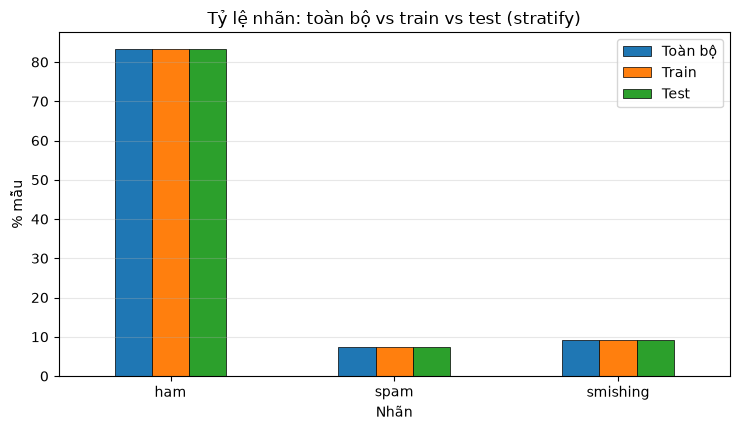

{
  "test_size": 0.2,
  "random_state": 42,
  "stratify": "label",
  "shuffle": true,
  "conflict_policy": "drop",
  "n_clean": 5797,
  "n_train": 4637,
  "n_test": 1160,
  "python": "3.15.2",
  "pandas": "3.1.1",
  "sklearn": "1.9.1"
}


In [13]:
pct = pd.DataFrame({
    "Toàn bộ": clean["label"].value_counts(normalize=True).reindex(LABELS_OK) * 100,
    "Train":   train_df["label"].value_counts(normalize=True).reindex(LABELS_OK) * 100,
    "Test":    test_df["label"].value_counts(normalize=True).reindex(LABELS_OK) * 100,
})
ax = pct.plot(kind="bar", figsize=(7.5, 4.4), edgecolor="black", linewidth=0.5)
ax.set_ylabel("% mẫu"); ax.set_xlabel("Nhãn"); ax.set_title("Tỷ lệ nhãn: toàn bộ vs train vs test (stratify)")
plt.xticks(rotation=0); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_FIGS / "05_phan_bo_nhan_train_test.png", dpi=200); plt.show()

# Lưu thông tin để tái lập
split_info = {
    "test_size": TEST_SIZE, "random_state": RANDOM_STATE, "stratify": "label", "shuffle": True,
    "conflict_policy": CONFLICT_POLICY,
    "n_clean": len(clean), "n_train": len(train_df), "n_test": len(test_df),
    "python": platform.python_version(), "pandas": pd.__version__, "sklearn": sklearn.__version__,
}
json.dump(split_info, open(PROCESSED_DIR / "split_info.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print(json.dumps(split_info, indent=2, ensure_ascii=False))

## Tổng kết & việc cần làm tiếp
**File tạo ra:**
| File | Nội dung |
|---|---|
| `data/processed/sms_phishing_clean.csv` | Dataset sạch (cột: id, orig_idx, label, label_id, text_clean, text_norm, url, email, phone) |
| `data/processed/train.csv`, `test.csv` | Tập huấn luyện / kiểm tra |
| `data/processed/split_info.json`, `label_mapping.json` | Tham số chia + phiên bản thư viện + mã nhãn |
| `outputs/tables/09…11_*.csv` | Bảng số mẫu theo bước, trước/sau, phân bố train/test |
| `outputs/tables/08_noi_dung_xung_dot_nhan.csv` | Danh sách nội dung bị gán 2 nhãn |
| `outputs/figures/04…05_*.png` | Biểu đồ trước/sau và train/test |

**Gợi ý ghi vào báo cáo:** nêu rõ (1) các bước làm sạch và lý do; (2) chính sách xung đột nhãn đã chọn; (3) bảng trước/sau; (4) `test_size = 0.2`, `stratify = label`, `random_state = 42`.

**Chuyển cho thành viên phụ trách huấn luyện mô hình:** dùng `train.csv` để huấn luyện và `test.csv` để đánh giá; thử `text_clean` và `text_norm`; dùng macro-F1 thay vì chỉ accuracy.